## A Mathematical Introduction to Machine Learning (5MA206), HT26
# Computer lab 1, part A: linear regression

**Instructions**
* Work through the notebook from top to bottom. Complete the code cells marked `# EDIT`, and answer the numbered
  questions **Q1, Q2, …** in the text cells below them.
* You may work in pairs. Write both names below.
* Before you submit: restart the kernel and run all cells (*Kernel* menu), and check that the notebook runs from start to
  finish without errors.
* Lab 1 consists of part A (this notebook) and part B (PCA). Submit both notebooks together as one zip file on Canvas.

**Name:** *Marcus Boivie*

In this lab we fit models of the form
$$
f(x)=\sum_{k=0}^{K-1}\theta_k\,\phi_k(x)=\boldsymbol\phi(x)^\top\boldsymbol\theta
$$
to data $\{(x_n,y_n)\}_{n=1}^N$. We choose the **features** $\phi_k(x)$ ourselves; they may be non-linear functions of $x$,
for example $\phi_k(x)=x^k$. The **parameters** $\theta_k$ are learned from the data. The model is linear in the parameters,
hence the name *linear regression* (MML Chapter 9, Lectures 3–4).

You will
* compute the maximum likelihood estimate of $\boldsymbol\theta$ (Lecture 3),
* see underfitting and overfitting, and compare the training error with the test error (Lectures 2 and 4),
* choose the model by cross-validation (Lecture 2),
* use ridge regression, which is MAP estimation with a Gaussian prior (Lecture 4),
* estimate the noise variance (Lecture 3).

Python counts from 0, so the code uses $n=0,\dots,N-1$ where the lectures use $n=1,\dots,N$.

**Packages.** The next cell installs the packages this lab needs, if they are missing (this needs an internet
connection). If they are already installed, as in Google Colab or a Miniforge environment set up as on the lab slides,
it only prints `Requirement already satisfied`. If it installed something new and an import below fails, restart the
kernel (*Kernel* menu) and run the notebook again.

In [1]:
%pip install numpy matplotlib


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [9]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## 1. The data

We generate data from a known function plus Gaussian noise, $y=f_{\mathrm{true}}(x)+\varepsilon$ with
$\varepsilon\sim\mathcal N(0,\sigma^2)$. In a real problem you know neither $f_{\mathrm{true}}$ nor $\sigma$; here we know
them, so that we can check what the methods do.

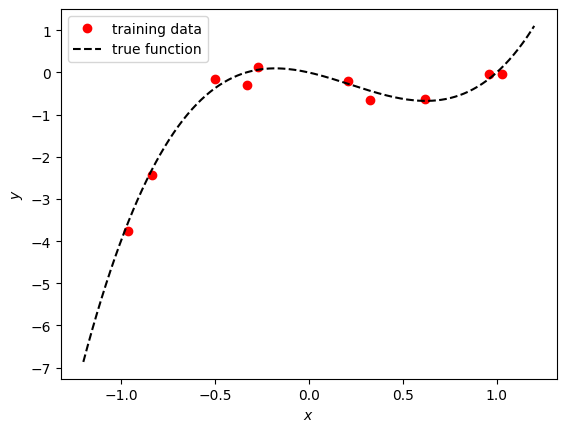

In [10]:
rng = np.random.default_rng(33)   # fixed seed: everybody gets the same data

def f_true(x):
    # the function behind the data (unknown in a real problem)
    return -1.0*x - 2.0*x**2 + 3.0*x**3

sigma = 0.2   # standard deviation of the noise (also unknown in a real problem)

def sample(x):
    # noisy observations y = f_true(x) + noise at the points x (an N x 1 array)
    return f_true(x) + sigma*rng.normal(size=x.shape)

N = 10
x_train = np.linspace(-1, 1, N).reshape(-1, 1) + 0.1*rng.normal(size=(N, 1))
y_train = sample(x_train)

xx = np.linspace(-1.2, 1.2, 200).reshape(-1, 1)   # a fine grid, only used for plotting

plt.figure()
plt.plot(x_train, y_train, 'ro', label='training data')
plt.plot(xx, f_true(xx), 'k--', label='true function')
plt.xlabel('$x$'); plt.ylabel('$y$'); plt.legend();

## 2. A straight line

The function `model` turns features and parameters into a function $x\mapsto\boldsymbol\phi(x)^\top\boldsymbol\theta$.
The features of a straight line are $\boldsymbol\phi(x)=(1,x)$, so $f(x)=\theta_0+\theta_1x$. For $N$ inputs,
`linear_features` returns the $N\times2$ feature matrix $\boldsymbol\Phi$, whose rows are $\boldsymbol\phi(x_n)^\top$.

In [11]:
def model(features, theta):
    # the model x -> phi(x)^T theta, where features(x) returns the N x K feature matrix Phi
    return lambda x: features(x) @ theta

def linear_features(x):
    # features phi(x) = (1, x): returns the N x 2 matrix Phi
    return np.hstack([np.ones_like(x), x])

Try to find a good line by hand: change `theta_guess` and rerun the cell.

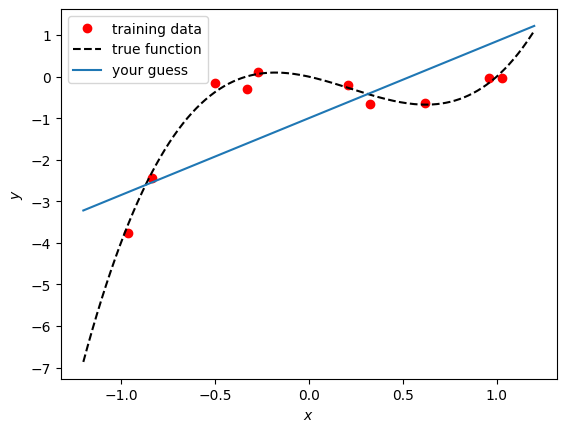

In [29]:
theta_guess = np.array([[-1], [1.85]]) # EDIT: try to find better values
f_guess = model(linear_features, theta_guess)

plt.figure()
plt.plot(x_train, y_train, 'ro', label='training data')
plt.plot(xx, f_true(xx), 'k--', label='true function')
plt.plot(xx, f_guess(xx), label='your guess')
plt.xlabel('$x$'); plt.ylabel('$y$'); plt.legend();

### Measuring the error
A systematic way to judge a model is the **root-mean-square error**
$$
\mathrm{RMSE}=\sqrt{\frac1N\sum_{n=1}^N\bigl(y_n-f(x_n)\bigr)^2}.
$$
Its square is the empirical risk with the squared loss (Lecture 1). Complete the function.

In [ ]:
def rmse(y, y_pred):
    # root-mean-square error between two N x 1 arrays
    return np.sqrt(np.mean((y - y_pred) ** 2)) # EDIT

print('training RMSE of your guess:', rmse(y_train, f_guess(x_train)))

training RMSE of your guess: 1.0398423436575337


### Maximum likelihood
With Gaussian noise, the maximum likelihood estimate $\boldsymbol\theta_{\mathrm{ML}}$ solves the **normal equations**
(Lecture 3)
$$
\boldsymbol\Phi^\top\boldsymbol\Phi\,\boldsymbol\theta=\boldsymbol\Phi^\top\boldsymbol y .
$$
Complete `fit_ml`. Use `np.linalg.solve` rather than computing the inverse $(\boldsymbol\Phi^\top\boldsymbol\Phi)^{-1}$:
solving the system is cheaper and more accurate.

theta_ML = [-0.83807334  1.15566739]


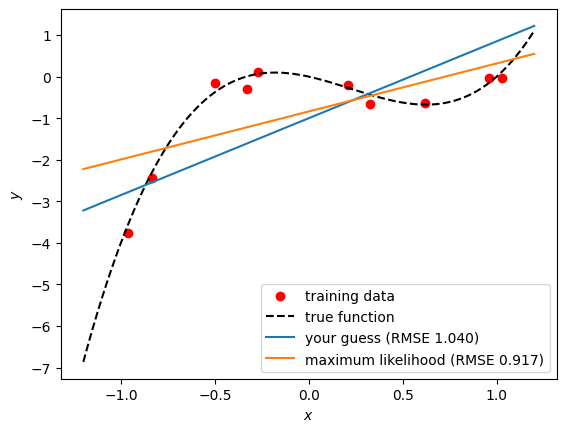

In [32]:
def fit_ml(Phi, y):
    # maximum likelihood estimate: the solution of Phi^T Phi theta = Phi^T y
    return np.linalg.solve(Phi.T @ Phi, Phi.T @ y)   # EDIT

Phi_line = linear_features(x_train)
theta_line = fit_ml(Phi_line, y_train)
f_line = model(linear_features, theta_line)
print('theta_ML =', theta_line.ravel())

plt.figure()
plt.plot(x_train, y_train, 'ro', label='training data')
plt.plot(xx, f_true(xx), 'k--', label='true function')
plt.plot(xx, f_guess(xx), label=f'your guess (RMSE {rmse(y_train, f_guess(x_train)):.3f})')
plt.plot(xx, f_line(xx), label=f'maximum likelihood (RMSE {rmse(y_train, f_line(x_train)):.3f})')
plt.xlabel('$x$'); plt.ylabel('$y$'); plt.legend();

**Q1.** Does the fitted line describe the data well? Does it describe the true function well?

**Q2.** Why does $\boldsymbol\theta_{\mathrm{ML}}$ give a smaller training RMSE than any other line, including your guess?
(Hint: Lecture 3. What does maximising the likelihood with Gaussian noise amount to?)

Q1: The fitted line does not describe the data well, as it is a compromise between the data points close to the extreme values of the true function. Considering the way the third-degree polynomial true function shapes, the fitted line as it is right now will fail to match possible data further away from the current data along the true function.

Q2: This is beacuse of the ...

The next cell computes the residual vector $\boldsymbol r=\boldsymbol y-\boldsymbol\Phi\boldsymbol\theta_{\mathrm{ML}}$ and
$\boldsymbol\Phi^\top\boldsymbol r$.

In [33]:
r = y_train - Phi_line @ theta_line
print('Phi^T r =', (Phi_line.T @ r).ravel())

Phi^T r = [ 3.33066907e-16 -1.54876556e-15]


**Q3.** $\boldsymbol\Phi^\top\boldsymbol r$ is zero up to rounding errors. Which equation says this? What does it mean
geometrically? (Lecture 4)

*Write your answer here.*

## 3. Polynomials of higher degree

A polynomial of degree $M$ has the features $\boldsymbol\phi(x)=(1,x,x^2,\dots,x^M)$, so $K=M+1$. Complete
`poly_features`, then try a few degrees $M$ in the cell after it (MML 9.2.2, Lecture 4).

In [ ]:
def poly_features(x, M):
    # features phi(x) = (1, x, ..., x^M): returns the N x (M+1) matrix Phi
    Phi = ...   # EDIT (hint: np.hstack([x**k for k in ...]))
    return Phi

In [ ]:
M = 2   # try different degrees
features = lambda x: poly_features(x, M)
theta = fit_ml(features(x_train), y_train)
f_M = model(features, theta)

plt.figure()
plt.plot(x_train, y_train, 'ro', label='training data')
plt.plot(xx, f_true(xx), 'k--', label='true function')
plt.plot(xx, f_M(xx), label=f'degree {M} (training RMSE {rmse(y_train, f_M(x_train)):.3f})')
plt.ylim(-6, 4); plt.xlabel('$x$'); plt.ylabel('$y$'); plt.legend();

Complete the loop, which computes the training RMSE for $M=0,1,\dots,9$.

In [ ]:
M_max = 9
train_rmse = np.zeros(M_max + 1)
for M in range(M_max + 1):
    features = lambda x: poly_features(x, M)
    theta = ...            # EDIT
    train_rmse[M] = ...    # EDIT

plt.figure()
plt.semilogy(range(M_max + 1), train_rmse, 'o-', label='training')
plt.xlabel('degree $M$'); plt.ylabel('RMSE'); plt.legend();

In [ ]:
for M in [1, 3, 6, 9]:
    Phi = poly_features(x_train, M)
    print(f'M = {M}: rank of Phi = {np.linalg.matrix_rank(Phi)}, condition number of Phi^T Phi = {np.linalg.cond(Phi.T @ Phi):.1e}')

**Q4.** Which degree $M$ gives the smallest training RMSE, and why? For which $M$ is the model underfitting, and for which
is it overfitting? (Plot a few of the fits above.)

**Q5.** The condition number of $\boldsymbol\Phi^\top\boldsymbol\Phi$ grows quickly with $M$. Why does that cause
numerical problems? What would happen for $M\ge N=10$? (Hint: the rank of $\boldsymbol\Phi$, Lecture 3.)

*Write your answer here.*

## 4. Training error and test error

Because we generated the data ourselves, we can draw a large **test set** from the same distribution. Its RMSE is close
to the root of the true risk (Lecture 2). In practice you only have your $N$ data points, and a test set may be used only
once, at the very end, to report the performance of the model you have chosen.

In [ ]:
x_test = rng.uniform(-1, 1, size=(1000, 1))
y_test = sample(x_test)

test_rmse = np.zeros(M_max + 1)
for M in range(M_max + 1):
    features = lambda x: poly_features(x, M)
    theta = fit_ml(features(x_train), y_train)
    test_rmse[M] = ...    # EDIT

plt.figure()
plt.semilogy(range(M_max + 1), train_rmse, 'o-', label='training')
plt.semilogy(range(M_max + 1), test_rmse, 's-', label='test')
plt.xlabel('degree $M$'); plt.ylabel('RMSE'); plt.legend();

**Q6.** Which degree has the smallest test RMSE? Compare with the true function. Describe overfitting in terms of the two
curves.

*Write your answer here.*

## 5. Choosing the degree by cross-validation

The test set must not be used to choose $M$: then it no longer measures the performance on new data (Lecture 2). Instead
we estimate the test error from the training data alone, with **leave-one-out cross-validation**: for each $n$, fit the
model to all training points except $(x_n,y_n)$, and compute the squared error of the prediction at $x_n$. The CV-RMSE is
the root of the average of these $N$ errors.

Complete `loocv_rmse`. The argument `fit` is the fitting method, for example `fit_ml`.

In [ ]:
def loocv_rmse(x, y, features, fit):
    # leave-one-out cross-validation estimate of the RMSE
    N = x.shape[0]
    errors = np.zeros(N)
    for n in range(N):
        keep = np.arange(N) != n           # every point except number n
        theta = ...            # EDIT: fit to the kept points
        errors[n] = ...        # EDIT: squared error of the prediction at x_n
    return np.sqrt(np.mean(errors))

M_cv = 8
cv_rmse = np.array([loocv_rmse(x_train, y_train, lambda x: poly_features(x, M), fit_ml) for M in range(M_cv + 1)])
M_best = int(np.argmin(cv_rmse))
print('degree chosen by cross-validation:', M_best)

plt.figure()
plt.semilogy(range(M_max + 1), train_rmse, 'o-', label='training')
plt.semilogy(range(M_max + 1), test_rmse, 's-', label='test')
plt.semilogy(range(M_cv + 1), cv_rmse, '^-', label='leave-one-out CV')
plt.xlabel('degree $M$'); plt.ylabel('RMSE'); plt.legend();

**Q7.** Which degree does cross-validation choose? Does it agree with the test error? Why does the cross-validation curve
stop at $M=8$, i.e. what would go wrong for $M=9$?

*Write your answer here.*

## 6. Ridge regression

Instead of choosing a small degree, we can keep a flexible model and penalise large parameters. **Ridge regression**
minimises
$$
\|\boldsymbol y-\boldsymbol\Phi\boldsymbol\theta\|^2+\lambda\|\boldsymbol\theta\|^2 ,
$$
and the minimiser is
$$
\boldsymbol\theta_{\mathrm{ridge}}=(\boldsymbol\Phi^\top\boldsymbol\Phi+\lambda\boldsymbol I)^{-1}\boldsymbol\Phi^\top\boldsymbol y .
$$

**Q8.** Derive this formula: compute the gradient of the objective with respect to $\boldsymbol\theta$ and set it to zero.

*Write your answer here.*

Complete `fit_ridge` (again with `np.linalg.solve`).

In [ ]:
def fit_ridge(Phi, y, lam):
    # ridge regression: minimise ||y - Phi theta||^2 + lam ||theta||^2
    K = Phi.shape[1]
    return ...   # EDIT

M = 9
features = lambda x: poly_features(x, M)
plt.figure()
plt.plot(x_train, y_train, 'ro', label='training data')
plt.plot(xx, f_true(xx), 'k--', label='true function')
for lam in [0, 1e-4, 1e-1]:
    theta = fit_ridge(features(x_train), y_train, lam)
    plt.plot(xx, model(features, theta)(xx), label=f'$M={M}$, $\\lambda$ = {lam:g}')
plt.ylim(-6, 4); plt.xlabel('$x$'); plt.ylabel('$y$'); plt.legend();

We now choose $\lambda$ for the degree $M=9$ by leave-one-out cross-validation. (With $\lambda>0$ this works even though
each fit uses only 9 points for 10 parameters.) Complete the computation of the CV-RMSE; the test RMSE is computed only
to compare.

In [ ]:
M = 9
features = lambda x: poly_features(x, M)
lams = np.logspace(-8, 1, 19)
cv_ridge = ...    # EDIT: array of LOOCV-RMSEs, one per lambda (hint: fit = lambda Phi, y: fit_ridge(Phi, y, lam))
test_ridge = np.array([rmse(y_test, model(features, fit_ridge(features(x_train), y_train, lam))(x_test)) for lam in lams])
lam_best = lams[np.argmin(cv_ridge)]
print(f'lambda chosen by cross-validation: {lam_best:.1e}')

plt.figure()
plt.loglog(lams, cv_ridge, '^-', label='leave-one-out CV')
plt.loglog(lams, test_ridge, 's-', label='test')
plt.xlabel('$\\lambda$'); plt.ylabel('RMSE'); plt.title(f'ridge regression, $M={M}$'); plt.legend();

Finally, the two models chosen by cross-validation are evaluated **once** on the test set.

In [ ]:
theta_A = fit_ml(poly_features(x_train, M_best), y_train)
theta_B = fit_ridge(poly_features(x_train, 9), y_train, lam_best)
print(f'A: degree {M_best}, maximum likelihood:   test RMSE = {rmse(y_test, poly_features(x_test, M_best) @ theta_A):.3f}')
print(f'B: degree 9, ridge with lambda = {lam_best:.0e}: test RMSE = {rmse(y_test, poly_features(x_test, 9) @ theta_B):.3f}')
print(f'noise level sigma = {sigma}')

**Q9.** Which $\lambda$ does cross-validation choose? Describe what happens for very small and for very large $\lambda$.

**Q10.** Ridge regression is MAP estimation with the prior $\boldsymbol\theta\sim\mathcal N(\boldsymbol 0,b^2\boldsymbol I)$,
with $\lambda=\sigma^2/b^2$ (Lecture 4). With $\sigma=0.2$, which prior standard deviation $b$ corresponds to the chosen
$\lambda$? Why does a prior that prefers small parameters help here?

**Q11.** Why does $\lambda>0$ also cure the numerical problems of Q5? (Hint: the eigenvalues of
$\boldsymbol\Phi^\top\boldsymbol\Phi+\lambda\boldsymbol I$.)

*Write your answer here.*

## 7. The noise variance

The maximum likelihood estimate of the noise variance is the mean squared residual on the training data (Lecture 3),
$$
\sigma^2_{\mathrm{ML}}=\frac1N\sum_{n=1}^N\bigl(y_n-\boldsymbol\phi(x_n)^\top\boldsymbol\theta_{\mathrm{ML}}\bigr)^2 ,
$$
and dividing by $N-K$ instead of $N$ gives an unbiased estimate. Compute both for the degree chosen by cross-validation.

In [ ]:
Phi = poly_features(x_train, M_best)
theta = fit_ml(Phi, y_train)
r = y_train - Phi @ theta
K = M_best + 1
s2_ml = ...         # EDIT
s2_unbiased = ...   # EDIT
print(f'sigma^2_ML = {s2_ml:.4f},  unbiased estimate = {s2_unbiased:.4f},  true sigma^2 = {sigma**2:.4f}')

With only $N=10$ training points the residuals say little about the shape of the noise distribution. The test set is
large, so we use its residuals to check the Gaussian noise model: the histogram should look like the density of
$\mathcal N(0,\hat\sigma^2)$.

In [ ]:
r_test = (y_test - poly_features(x_test, M_best) @ theta).ravel()
s = np.sqrt(s2_unbiased)
t = np.linspace(-4*s, 4*s, 200)
plt.figure()
plt.hist(r_test, bins=30, density=True, alpha=0.5, label='test residuals')
plt.plot(t, np.exp(-t**2/(2*s**2))/np.sqrt(2*np.pi*s**2), 'k', label='$\\mathcal{N}(0,\\hat\\sigma^2)$')
plt.xlabel('residual'); plt.legend();

**Q12.** Which of the two estimates is closer to the true $\sigma^2=0.04$? Why is $\sigma^2_{\mathrm{ML}}$ too small on
average? (Hint: it is a training error, Lecture 2.) Does the histogram support the Gaussian noise model?

*Write your answer here.*

## Optional extras
* Try other features, for example a Fourier basis $\phi_k(x)=\cos(k\pi x)$ and $\sin(k\pi x)$.
* Repeat the experiment with another seed, or with more training points ($N=30$). What changes?
* Find out how `sklearn.linear_model.LinearRegression` and `Ridge` do the same computations.